# Yolo Example - YoReX
This notebook demonstrates how to use YoReX to explain a YOLOv11 model.
Demonstration using the COCO dataset.
This is NOT the Library version of YoReX and is not supported. We will be using command line version of **YoReX**.


In [11]:
from PIL import Image

import rex_xai
import subprocess
import torch as tt
import os
import sys
from ultralytics import YOLO
from matplotlib import pyplot as plt
import numpy as np
%matplotlib inline
current_folder = os.path.dirname(os.path.abspath(sys.argv[0])) if "__file__" in locals() else os.getcwd()

### Helper Functions
- load image
- visualize the yolo and rtdetr predictions
- visualize the yorex explanation

In [2]:
def load_image(image_path):
    return Image.open(image_path).convert("RGB")

In [3]:
def visualize_detections(image_path, detections, model):
    image = load_image(image_path)
    plt.figure(figsize=(12, 8))
    plt.imshow(image)
    ax = plt.gca()
    for det in detections:
        x1, y1, x2, y2 = det.xyxy[0].tolist()
        conf, cls = det.conf.item(), det.cls.item()
        width = x2 - x1
        height = y2 - y1
        rect = plt.Rectangle((x1, y1), width, height, edgecolor='red', facecolor='none', linewidth=2)
        ax.add_patch(rect)
        label = f"{model.names[int(cls)]}: {conf:.2f}"
        plt.text(x1, y1 - 10, label, color='red', fontsize=12)
    plt.axis('off')
    plt.show()

### Set up the model and data

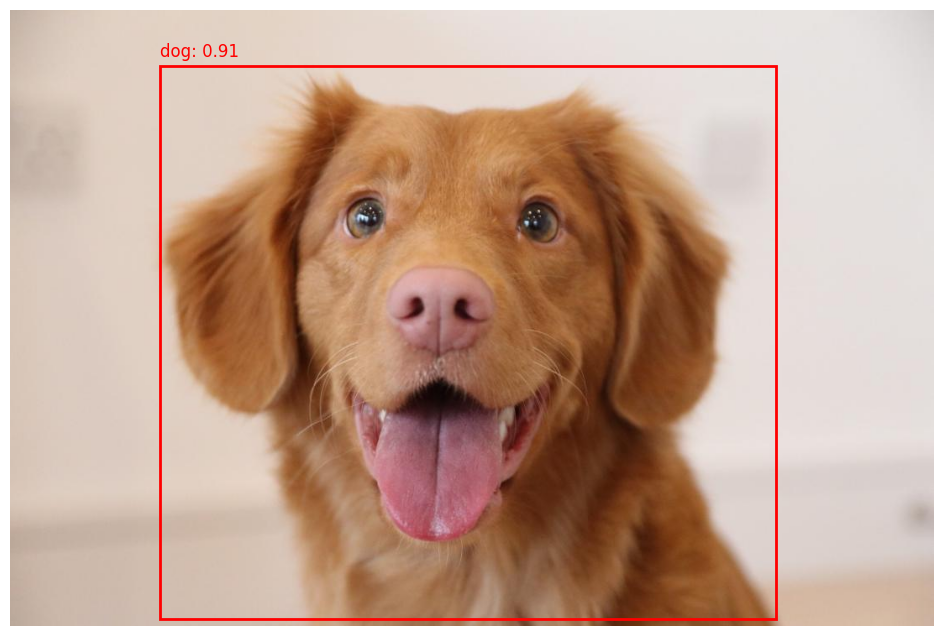

In [4]:
yolo = YOLO("yolo11n.pt")
yolo.eval()
parent_folder = os.path.dirname(current_folder)
example = f"{parent_folder}/tests/test_data/dog.jpg"

yolo_pred = yolo.predict(source=example, conf=0.25, verbose=False)
visualize_detections(example, yolo_pred[0].boxes, yolo)

### Set up the YoReX command line arguments

In [5]:
# Check if ReX is installed
!{ReX --version}

0.4.2


In [7]:
YOLO_REX_SCRIPT = f"{parent_folder}/scripts/yolo.py" # Path to the script that has prediction function, model_shape etc. defined in this script
RTDETR_REX_SCRIPT = f"{parent_folder}/scripts/rfdetr.py"


os.makedirs("/tmp/yorex_output", exist_ok=True)

# create a <>.toml in this dir
example_toml = f"/tmp/yorex_output/rex.toml"
with open(example_toml, "w") as f:
    f.write(f"[rex]\nseed = 0\ngpu = false\n[rex.onnx]\n[causal]\n[causal.distribution]\n[explanation]\nchunk_size = 100\n[explanation.spatial]\n[explanation.multi]\n[explanation.evaluation]")

yolo_commands = [
    "ReX",
    example,
    "--script",
    YOLO_REX_SCRIPT,
    "--output", f"/tmp/yorex_output/yo-rex-output.jpg",
    "--dump", f"/tmp/yorex_output/yo-rex-dump.csv",
    "--config", example_toml,
]

# Run the YoReX command line tool
subprocess.run(yolo_commands, check=True)

Preprocessing image: /home/melanenavaratnarajah/Documents/clean/ReX/tests/test_data/dog.jpg with shape: torch.Size([734, 1100, 3]) min of tensor: tensor(0.) max of tensor: tensor(255.) mean of tensor: tensor(166.4450) std of tensor: tensor(62.5443) 


Extracting global explanation:  27%|██▋       | 2213/8074 [02:23<06:20, 15.40it/s]


Saving to /tmp/yorex_output/dog_responsibility.npy


CompletedProcess(args=['ReX', '/home/melanenavaratnarajah/Documents/clean/ReX/tests/test_data/dog.jpg', '--script', '/home/melanenavaratnarajah/Documents/clean/ReX/scripts/yolo.py', '--output', '/tmp/yorex_output/yo-rex-output.jpg', '--dump', '/tmp/yorex_output/yo-rex-dump.csv', '--config', '/tmp/yorex_output/rex.toml'], returncode=0)

Looking Yo-ReX Outputs

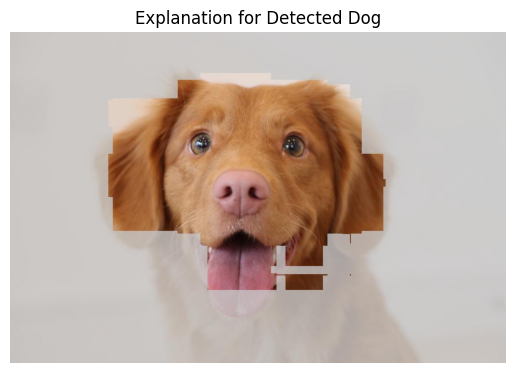

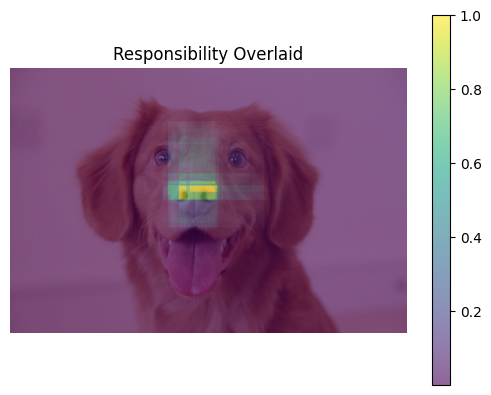

In [17]:
output_image_path = "/tmp/yorex_output/yo-rex-output.jpg"
if os.path.exists(output_image_path):
    plt.imshow(load_image(output_image_path))
    plt.axis('off')
    plt.title('Explanation for Detected Dog')
    plt.show()
else:
    print(f"Output image not found at {output_image_path}")

resp_map_path = "/tmp/yorex_output/dog_responsibility.npy"
if os.path.exists(resp_map_path):
    resp_map = np.load(resp_map_path)
    plt.imshow(load_image(example))
    plt.imshow(resp_map, alpha=0.6)
    plt.colorbar()
    plt.axis('off')
    plt.title("Responsibility Overlaid")
    plt.show()
    



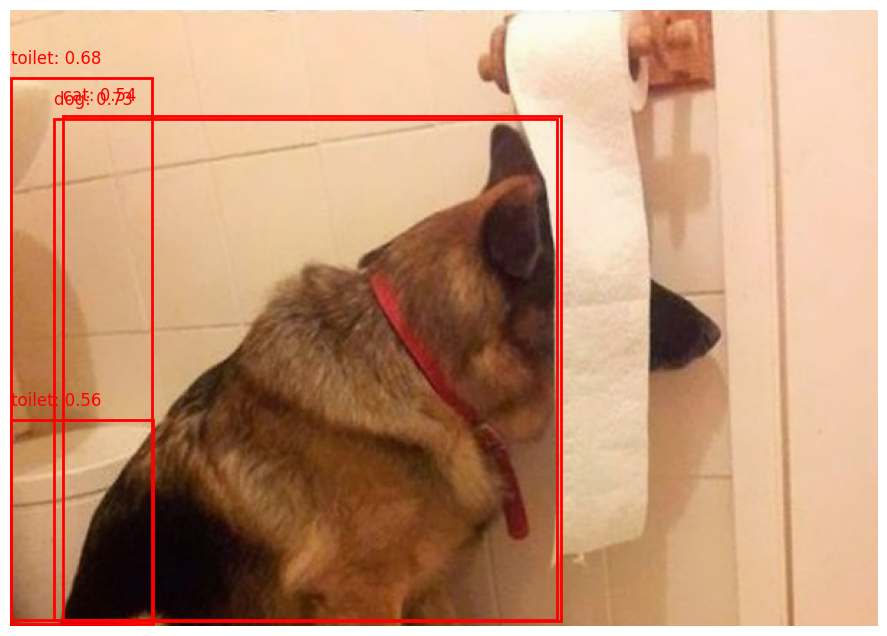

In [21]:
new_example = os.path.dirname(example) + "/dog_hide.jpg"
yolo_commands[1] = new_example
yolo_pred = yolo.predict(source=new_example, verbose=False)
visualize_detections(new_example, yolo_pred[0].boxes, yolo)

In [22]:
# Run Yo-ReX on this new example:
subprocess.run(yolo_commands, check=True)

Preprocessing image: /home/melanenavaratnarajah/Documents/clean/ReX/tests/test_data/dog_hide.jpg with shape: torch.Size([429, 604, 3]) min of tensor: tensor(0.) max of tensor: tensor(255.) mean of tensor: tensor(152.2551) std of tensor: tensor(71.3867) 


Extracting global explanation:   7%|▋         | 194/2591 [00:12<02:30, 15.95it/s]


Saving to /tmp/yorex_output/dog_hide_responsibility_dog_0.8899.npy
Saving to /tmp/yorex_output/dog_hide_responsibility_toilet_0.3894.npy
Saving to /tmp/yorex_output/dog_hide_responsibility_toilet_0.3243.npy
Saving to /tmp/yorex_output/dog_hide_explanation_dog_0.8899.npy
Saving to /tmp/yorex_output/dog_hide_explanation_toilet_0.3894.npy
Saving to /tmp/yorex_output/dog_hide_explanation_toilet_0.3243.npy


CompletedProcess(args=['ReX', '/home/melanenavaratnarajah/Documents/clean/ReX/tests/test_data/dog_hide.jpg', '--script', '/home/melanenavaratnarajah/Documents/clean/ReX/scripts/yolo.py', '--output', '/tmp/yorex_output/yo-rex-output.jpg', '--dump', '/tmp/yorex_output/yo-rex-dump.csv', '--config', '/tmp/yorex_output/rex.toml'], returncode=0)

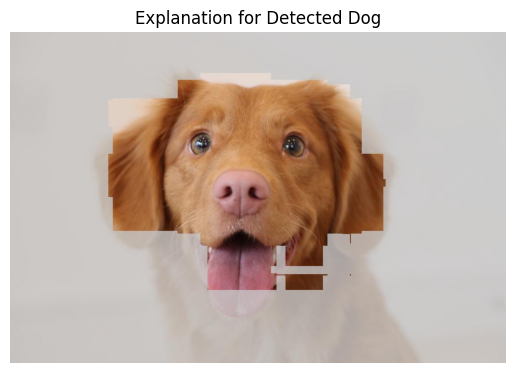

In [23]:
plt.imshow(load_image(output_image_path))
plt.axis('off')
plt.title('Explanation for Detected Dog')
plt.show()